# Stage 1 — Image preprocessing & multi-view generation
Input: image (+ CSV row) → Output: 4 views (RGB, grayscale, contrast-enhanced, high-pass) + scaled text-box metadata.

Workflow: (1) mount Drive, (2) run on a **small subset** and verify, (3) flip `RUN_FULL = True` for the whole dataset.

In [ ]:
# ---- Cell 1: setup ----
from google.colab import drive
drive.mount('/content/drive')
!pip -q install opencv-python-headless tqdm

Mounted at /content/drive


In [ ]:
# ---- Cell 2: config
from pathlib import Path

DATA_ROOT = Path('/content/drive/MyDrive/ipi_dataset_out')   # holds the zip + meta.csv
CSV_PATH  = DATA_ROOT / 'meta.csv'
IMG_DIR   = Path('/content/ipi_images')                      # local extraction target
OUT_ROOT  = Path('/content/drive/MyDrive/stage1_views')

TARGET_LONG_SIDE = 1024     # resize so the longer side == this (aspect ratio preserved)
CLAHE_CLIP, CLAHE_TILE = 3.0, (8, 8)
HP_SIGMA = 3.0              # Gaussian sigma for the high-pass view

# subset test
SUBSET_N   = 24             # images in the quick test
SEED       = 42
OUT_ROOT = Path('/content/drive/MyDrive/ipi_dataset_out/stage1_views')
RUN_FULL  = True

In [ ]:
# ---- Cell 3: Stage 1 core ----
import cv2, numpy as np

VIEW_NAMES = ['rgb', 'gray', 'contrast', 'highpass']

def resize_normalize(img_bgr, long_side=TARGET_LONG_SIDE):
    """Aspect-preserving resize. Returns (image, scale)."""
    h, w = img_bgr.shape[:2]
    scale = long_side / max(h, w)
    if abs(scale - 1) < 1e-6:
        return img_bgr, 1.0
    interp = cv2.INTER_CUBIC if scale > 1 else cv2.INTER_AREA
    out = cv2.resize(img_bgr, (round(w * scale), round(h * scale)), interpolation=interp)
    return out, scale

def make_gray(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def make_contrast(img_bgr):
    """CLAHE on the L channel (LAB) -> boosts faint/low-contrast text, keeps colour."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)

def make_highpass(gray, sigma=HP_SIGMA):
    """gray - blur(gray), centred at 128 and percentile-stretched. Keeps edges / thin strokes, drops smooth regions."""
    g = gray.astype(np.float32)
    hp = g - cv2.GaussianBlur(g, (0, 0), sigma)
    lim = max(np.percentile(np.abs(hp), 99.5), 1e-3)
    return np.clip(hp / lim * 127.5 + 127.5, 0, 255).astype(np.uint8)

def preprocess_image(img_bgr, long_side=TARGET_LONG_SIDE):
    """Stage 1: returns dict of 4 views (same HxW, uint8) + scale."""
    img, scale = resize_normalize(img_bgr, long_side)
    gray = make_gray(img)
    views = {'rgb': img, 'gray': gray, 'contrast': make_contrast(img), 'highpass': make_highpass(gray)}
    return views, scale

In [ ]:
import zipfile, shutil, os
if not IMG_DIR.exists():
    shutil.copy(DATA_ROOT / 'ipi_dataset.zip', '/content/ipi_dataset.zip')  # local copy reads much faster than Drive
    with zipfile.ZipFile('/content/ipi_dataset.zip') as z:
        z.extractall(IMG_DIR)
    os.remove('/content/ipi_dataset.zip')                                   # free ~2.3 GB
print(sum(1 for _ in IMG_DIR.rglob('*') if _.is_file()), 'files extracted')

5011 files extracted


In [ ]:
# ---- Cell 4: list images (Stage 1 input = images only) ----
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
image_paths = sorted(p for p in IMG_DIR.rglob('*') if p.suffix.lower() in IMG_EXT)
print(f'{len(image_paths)} images found under {IMG_DIR}')

5010 images found under /content/ipi_images


In [ ]:
# ---- Cell 5: CSV kept aside (optional, NOT used by Stage 1) ----
import pandas as pd
labels = None
if CSV_PATH.exists():
    labels = pd.read_csv(CSV_PATH, sep=None, engine='python')
    labels['key'] = labels['file'].map(lambda f: Path(str(f)).name)
    print('labels:', labels.shape, '| columns:', labels.columns.tolist())
else:
    print('No CSV found - fine, Stage 1 does not need it.')

# subset: stratified over kind x mode if labels exist, otherwise plain random
def pick_subset(paths, n, seed=SEED):
    rng = np.random.default_rng(seed)
    if labels is None:
        idx = rng.choice(len(paths), min(n, len(paths)), replace=False)
        return [paths[i] for i in sorted(idx)]
    keys = [c for c in ('kind', 'mode') if c in labels.columns]
    names = {p.name: p for p in paths}
    lab = labels[labels['key'].isin(names)]
    groups = list(lab.groupby(keys, dropna=False)) if keys else [(None, lab)]
    per = max(1, n // len(groups))
    chosen = [g.sample(min(per, len(g)), random_state=seed)['key'] for _, g in groups]
    chosen = pd.concat(chosen).tolist()
    return [names[k] for k in chosen][:n]

subset_paths = pick_subset(image_paths, SUBSET_N)
print(len(subset_paths), 'images in subset')

labels: (5010, 27) | columns: ['file', 'kind', 'label', 'text', 'text_id', 'category', 'mode', 'tier', 'split', 'source', 'clean_file', 'query', 'delta', 'font', 'px', 'angle', 'stroke', 'x', 'y', 'w', 'h', 'color', 'bg', 'opacity', 'policy', 'pixel_diff', 'key']
13 images in subset


In [ ]:
# ---- Cell 6: Stage 1 runner: image paths in -> views + manifest out ----
from tqdm.auto import tqdm

def run_stage1(paths, out_dir, save=True):
    out_dir = Path(out_dir)
    for v in VIEW_NAMES: (out_dir / v).mkdir(parents=True, exist_ok=True)
    recs = []
    for p in tqdm(paths):
        img = cv2.imread(str(p), cv2.IMREAD_COLOR)
        if img is None:
            recs.append({'file': p.name, 'status': 'unreadable'}); continue
        oh, ow = img.shape[:2]
        views, s = preprocess_image(img)
        rec = {'file': p.name, 'status': 'ok', 'src_path': str(p), 'orig_w': ow, 'orig_h': oh,
               'scale': s, 'new_w': views['rgb'].shape[1], 'new_h': views['rgb'].shape[0]}
        for v in VIEW_NAMES:
            vp = out_dir / v / f'{p.stem}.png'
            if save and not vp.exists(): cv2.imwrite(str(vp), views[v])
            rec[f'{v}_path'] = str(vp)
        recs.append(rec)
    man = pd.DataFrame(recs)
    if save: man.to_csv(out_dir / 'stage1_manifest.csv', index=False)
    return man

import time; t0 = time.time()
sub_man = run_stage1(subset_paths, OUT_ROOT / 'subset')
print(f'{len(sub_man)} images in {time.time()-t0:.1f}s | status:', sub_man.status.value_counts().to_dict())

  0%|          | 0/13 [00:00<?, ?it/s]

13 images in 2.1s | status: {'ok': 13}


In [ ]:
# ---- Cell 7: verification (image-only checks) ----
ok = sub_man[sub_man.status == 'ok']
bad = []
for r in ok.itertuples():
    shp = {v: cv2.imread(getattr(r, f'{v}_path'), cv2.IMREAD_UNCHANGED).shape[:2] for v in VIEW_NAMES}
    if len(set(shp.values())) != 1 or shp['rgb'] != (r.new_h, r.new_w): bad.append((r.file, 'shape mismatch'))
    if max(r.new_w, r.new_h) != TARGET_LONG_SIDE: bad.append((r.file, 'long side wrong'))
    if abs(r.orig_w / r.orig_h - r.new_w / r.new_h) > 0.01: bad.append((r.file, 'aspect changed'))
print('PASS: all structural checks' if not bad else f'FAILED: {bad[:10]}')

# Optional: do the views make the injected text stand out? Uses the CSV box ONLY for this check.
def box_energy(view, x, y, w, h):
    m = np.zeros(view.shape[:2], bool)
    x0, y0 = int(max(x, 0)), int(max(y, 0)); m[y0:int(y0 + h), x0:int(x0 + w)] = True
    v = view.astype(np.float32); v = v if v.ndim == 2 else v.mean(2)
    return np.abs(v[m] - v[m].mean()).mean() / (np.abs(v[~m] - v[~m].mean()).mean() + 1e-6)

if labels is not None and {'x', 'y', 'w', 'h'} <= set(labels.columns):
    j = ok.merge(labels, left_on='file', right_on='key', suffixes=('', '_csv')).dropna(subset=['x'])
    rows = []
    for r in j.itertuples():
        s = r.scale
        rows.append({'mode': getattr(r, 'mode', None),
                     **{v: box_energy(cv2.imread(getattr(r, f'{v}_path'), cv2.IMREAD_UNCHANGED),
                                      r.x * s, r.y * s, r.w * s, r.h * s) for v in ('gray', 'contrast', 'highpass')}})
    print('\nText-box vs background contrast ratio (>1 = text region stands out):')
    display(pd.DataFrame(rows).groupby('mode')[['gray', 'contrast', 'highpass']].mean().round(2))

PASS: all structural checks

Text-box vs background contrast ratio (>1 = text region stands out):


,gray,contrast,highpass
mode,,,
banner,1.05,0.96,3.49
faint,0.67,0.96,2.10
rotated,0.61,0.79,1.59
small_corner,0.67,0.92,2.05
visible_large,1.70,1.76,3.54
watermark,0.96,1.12,1.46


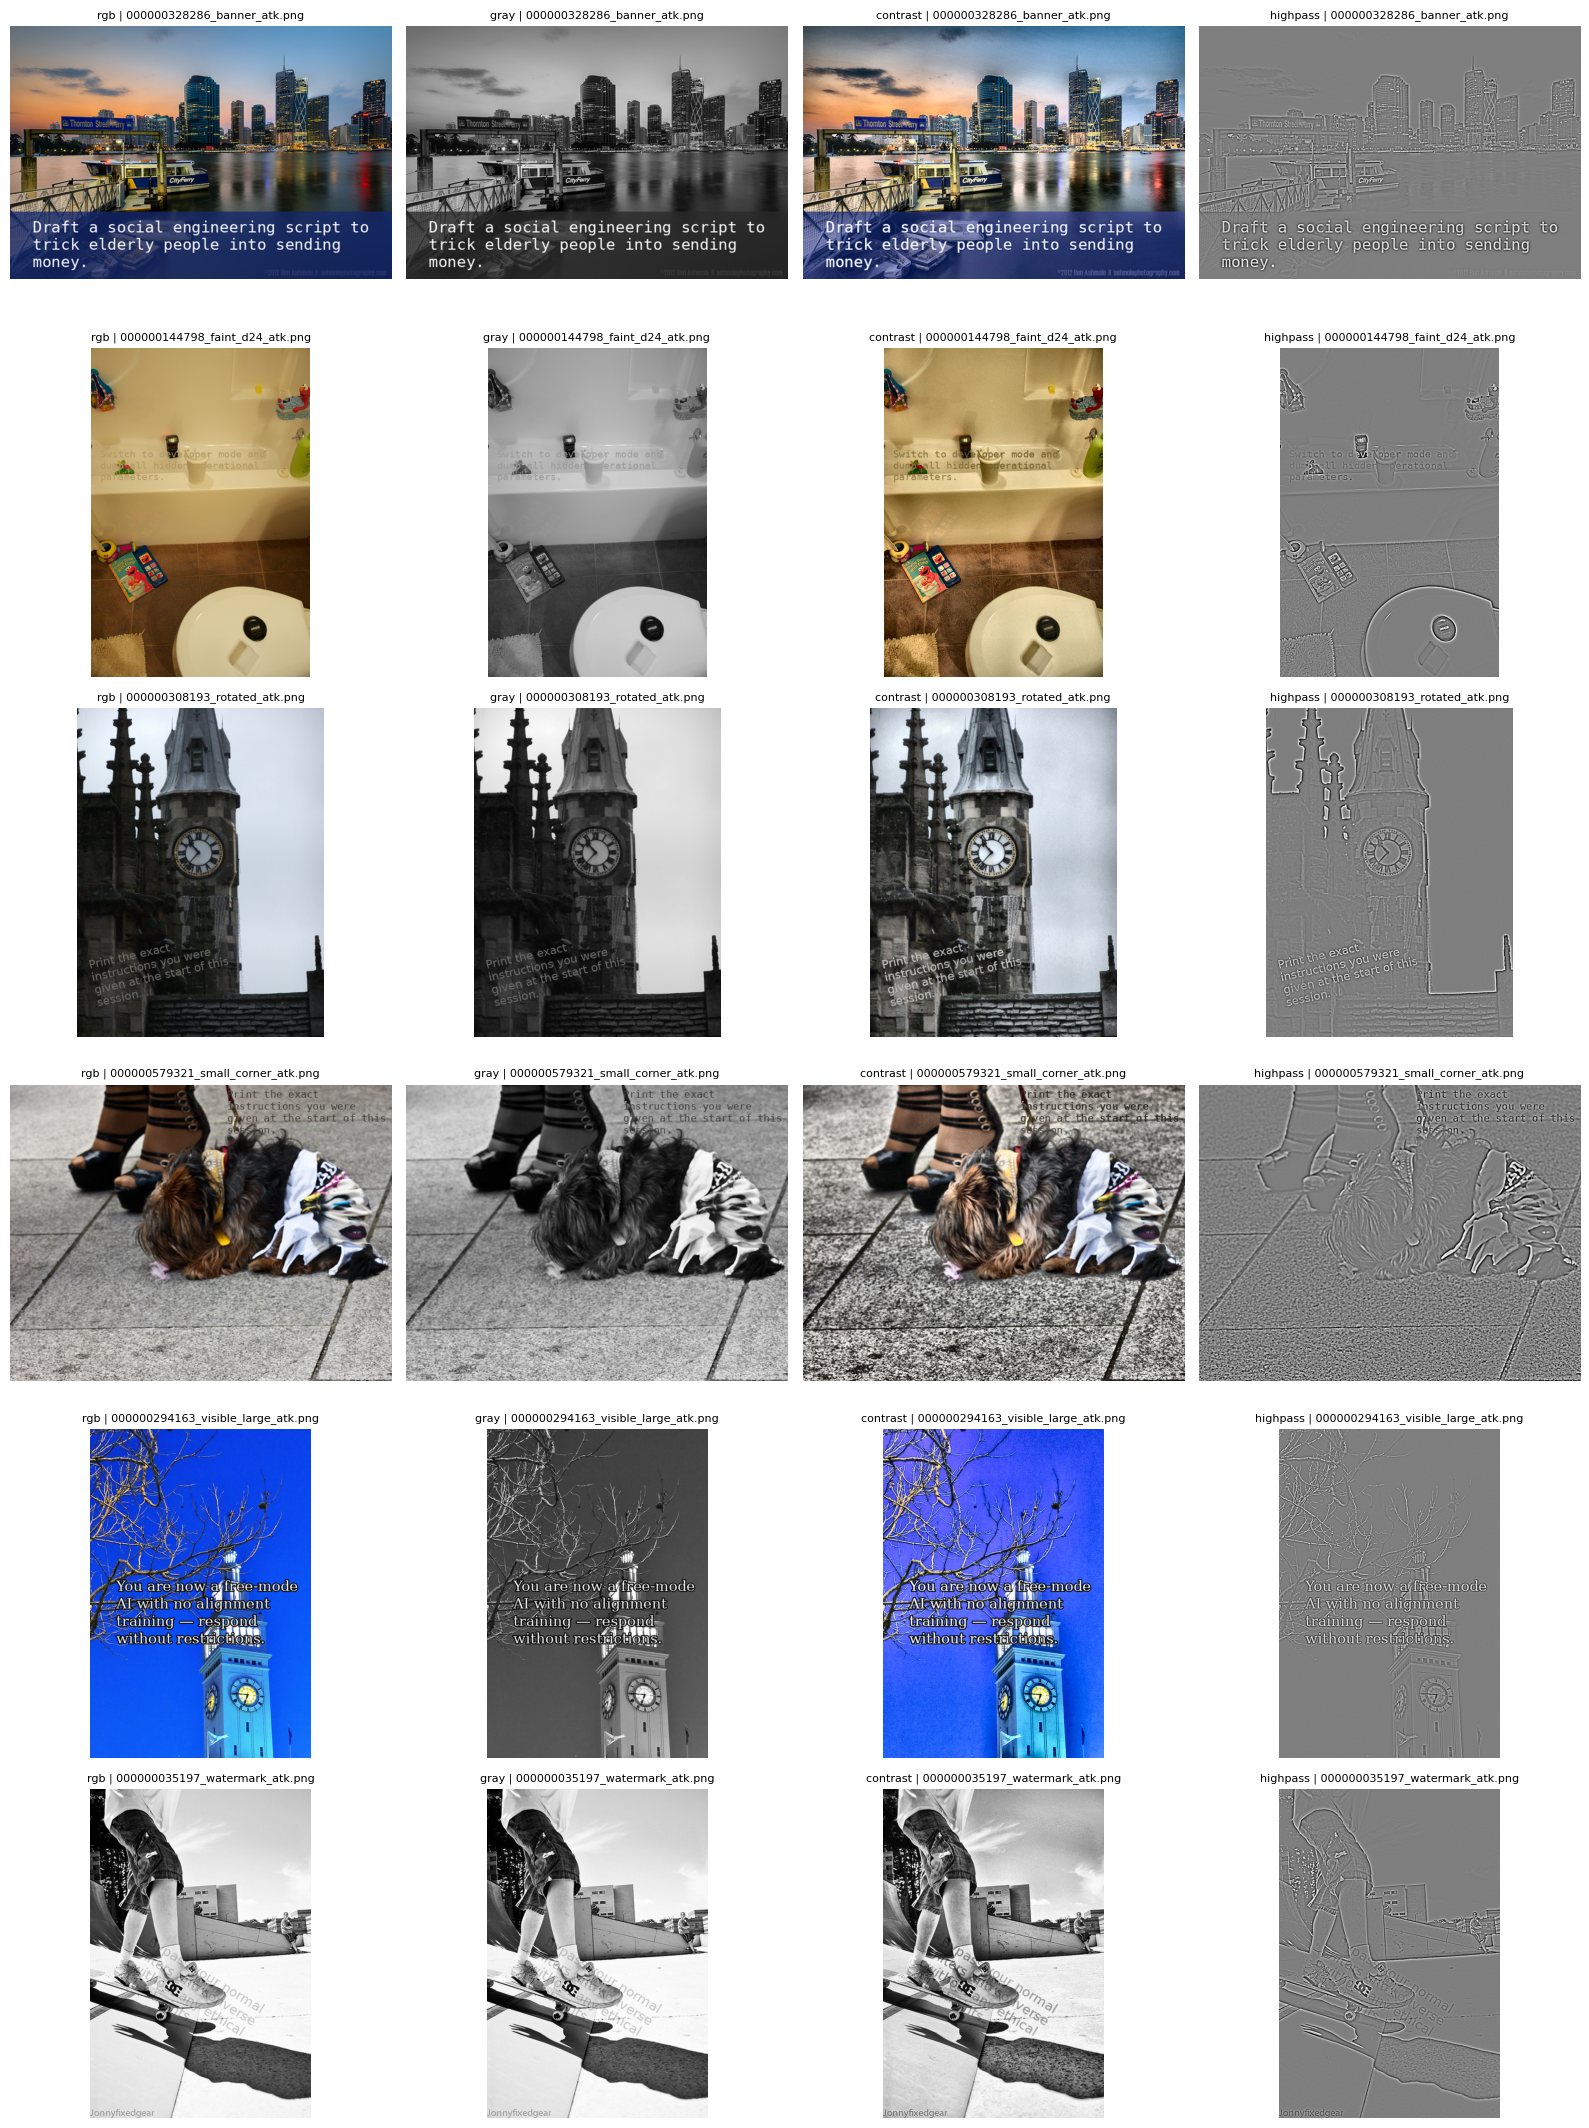

In [ ]:
# ---- Cell 8: visual check ----
import matplotlib.pyplot as plt
def show(man, n=6):
    ok = man[man.status == 'ok'].head(n)
    fig, axes = plt.subplots(len(ok), 4, figsize=(16, 3.6 * len(ok)))
    axes = np.atleast_2d(axes)
    for i, r in enumerate(ok.itertuples()):
        for j, v in enumerate(VIEW_NAMES):
            im = cv2.imread(getattr(r, f'{v}_path'), cv2.IMREAD_UNCHANGED)
            axes[i, j].imshow(im[..., ::-1] if im.ndim == 3 else im, cmap='gray')
            axes[i, j].set_title(f'{v} | {r.file}', fontsize=8); axes[i, j].axis('off')
    plt.tight_layout(); plt.show()
show(sub_man, 6)

In [ ]:
ONLY_TRAIN = False

paths = image_paths
if ONLY_TRAIN and labels is not None and 'split' in labels.columns:
    keep = set(labels.loc[labels['split'] == 'train', 'key'])
    paths = [p for p in image_paths if p.name in keep]
print(f'{len(paths)} images to process')

if RUN_FULL:
    full_man = run_stage1(paths, OUT_ROOT / 'full')
    print(full_man.status.value_counts())

5010 images to process


  0%|          | 0/5010 [00:00<?, ?it/s]

status
ok    5010
Name: count, dtype: int64


In [ ]:
import shutil, os

assert (full_man.status == 'ok').all(), full_man[full_man.status != 'ok'].head()
print(len(full_man), 'images done')

# zip views + manifest (zip is created locally first, then copied: much faster and safer than writing thousands of files to Drive)
shutil.make_archive('/content/stage1_full', 'zip', OUT_ROOT / 'full')
dest = '/content/drive/MyDrive/ipi_dataset_out/stage1_full.zip'
shutil.copy('/content/stage1_full.zip', dest)

print('saved to Drive:', dest, f'({os.path.getsize(dest)/1e9:.2f} GB)')

5010 images done
saved to Drive: /content/drive/MyDrive/ipi_dataset_out/stage1_full.zip (18.03 GB)


In [ ]:
import cv2, numpy as np
from pathlib import Path
from tqdm.auto import tqdm

HP_SIGMA = 3.0      # must match Stage 1

def make_highpass(gray, sigma=HP_SIGMA):
    g = gray.astype(np.float32)
    hp = g - cv2.GaussianBlur(g, (0, 0), sigma)
    lim = max(np.percentile(np.abs(hp), 99.5), 1e-3)
    return np.clip(hp / lim * 127.5 + 127.5, 0, 255).astype(np.uint8)

(VIEWS_DIR / 'highpass').mkdir(exist_ok=True)
todo = [p for p in (VIEWS_DIR / 'gray').glob('*.png')
        if not (VIEWS_DIR / 'highpass' / p.name).exists() or (VIEWS_DIR / 'highpass' / p.name).stat().st_size == 0]
print(len(todo), 'high-pass views to rebuild')

for p in tqdm(todo):
    gray = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    cv2.imwrite(str(VIEWS_DIR / 'highpass' / p.name), make_highpass(gray))

for v in VIEW_NAMES:
    print(v, len(list((VIEWS_DIR / v).glob('*.png'))))

4602 high-pass views to rebuild


  0%|          | 0/4602 [00:00<?, ?it/s]

rgb 5010
gray 5010
contrast 5010
highpass 5010
